In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Marketing_Campaign_Raw_Data.csv to Marketing_Campaign_Raw_Data.csv


In [3]:
df = pd.read_csv('Marketing_Campaign_Raw_Data.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.head()

,Campaign_ID,Campaign_Name,Channel,Start_Date,End_Date,Budget_Spent (INR),Impressions,Clicks,Conversions,Revenue_Generated (INR)
0,C001,UrbanKart Mobiles Independence Day Special,Email,2025-02-07,2025-02-12,58823,596216.0,22537.0,768.0,1215132.0
1,C002,UrbanKart Beauty Republic Day Sale,Google Ads,2025-10-17,2025-10-22,104907,215178.0,9059.0,784.0,1102850.0
2,C003,UrbanKart Beauty Diwali Offer,Google Ads,2025-05-29,2025-06-08,259749,2092780.0,50436.0,3263.0,NaN
3,C004,UrbanKart Beauty Back to School,Social Media,2025-10-16,2025-10-23,40624,202474.0,6054.0,314.0,740320.0
4,C005,UrbanKart Mobiles Mega Saving Days,Social Media,2025-05-05,2025-05-15,46457,233831.0,7202.0,522.0,2427927.0


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (220, 10)


df.info()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Campaign_ID              220 non-null    object 
 1   Campaign_Name            220 non-null    object 
 2   Channel                  220 non-null    object 
 3   Start_Date               220 non-null    object 
 4   End_Date                 220 non-null    object 
 5   Budget_Spent (INR)       220 non-null    int64  
 6   Impressions              218 non-null    float64
 7   Clicks                   219 non-null    float64
 8   Conversions              217 non-null    float64
 9   Revenue_Generated (INR)  216 non-null    float64
dtypes: float64(4), int64(1), object(5)
memory usage: 17.3+ KB


In [7]:
df.describe()

,Budget_Spent (INR),Impressions,Clicks,Conversions,Revenue_Generated (INR)
count,220.000000,2.180000e+02,219.000000,217.000000,2.160000e+02
mean,214417.218182,2.889908e+06,21775.374429,1195.622120,3.167709e+06
std,195301.892658,6.596510e+06,13325.008770,1071.987737,4.261034e+06
min,6737.000000,5.785700e+04,2916.000000,40.000000,2.536300e+04
25%,58910.750000,3.773552e+05,11477.500000,423.000000,7.020910e+05
50%,172587.000000,7.472940e+05,19708.000000,874.000000,1.567792e+06
75%,279782.000000,1.961178e+06,28930.000000,1643.000000,4.095687e+06
max,883183.000000,6.325750e+07,66507.000000,5701.000000,2.462469e+07


In [9]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values Before Cleaning:
Campaign_ID                0
Campaign_Name              0
Channel                    0
Start_Date                 0
End_Date                   0
Budget_Spent (INR)         0
Impressions                2
Clicks                     1
Conversions                3
Revenue_Generated (INR)    4
dtype: int64

Total Missing Values:
10


In [10]:
df.drop_duplicates(inplace=True)

print("Duplicate records removed successfully!")
print("Remaining Rows:", len(df))

Duplicate records removed successfully!
Remaining Rows: 220


In [11]:
numeric_columns = [
    'Impressions',
    'Clicks',
    'Conversions',
    'Revenue_Generated (INR)'
]

for col in numeric_columns:
    df[col] = df[col].fillna(
        df.groupby('Channel')[col].transform('median')
    )

print("Missing values handled successfully!")

Missing values handled successfully!


In [12]:
df['Start_Date'] = pd.to_datetime(df['Start_Date'])
df['End_Date'] = pd.to_datetime(df['End_Date'])

print("Date columns converted successfully!")

Date columns converted successfully!


In [13]:
print(df.dtypes)

Campaign_ID                        object
Campaign_Name                      object
Channel                            object
Start_Date                 datetime64[ns]
End_Date                   datetime64[ns]
Budget_Spent (INR)                  int64
Impressions                       float64
Clicks                            float64
Conversions                       float64
Revenue_Generated (INR)           float64
dtype: object


In [14]:
print("CLEANED DATASET VALIDATION")

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Records:")
display(df.head())

CLEANED DATASET VALIDATION

Dataset Shape: (220, 10)

Missing Values:
Campaign_ID                0
Campaign_Name              0
Channel                    0
Start_Date                 0
End_Date                   0
Budget_Spent (INR)         0
Impressions                0
Clicks                     0
Conversions                0
Revenue_Generated (INR)    0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0

First 5 Records:


,Campaign_ID,Campaign_Name,Channel,Start_Date,End_Date,Budget_Spent (INR),Impressions,Clicks,Conversions,Revenue_Generated (INR)
0,C001,UrbanKart Mobiles Independence Day Special,Email,2025-02-07,2025-02-12,58823,596216.0,22537.0,768.0,1215132.0
1,C002,UrbanKart Beauty Republic Day Sale,Google Ads,2025-10-17,2025-10-22,104907,215178.0,9059.0,784.0,1102850.0
2,C003,UrbanKart Beauty Diwali Offer,Google Ads,2025-05-29,2025-06-08,259749,2092780.0,50436.0,3263.0,4341443.0
3,C004,UrbanKart Beauty Back to School,Social Media,2025-10-16,2025-10-23,40624,202474.0,6054.0,314.0,740320.0
4,C005,UrbanKart Mobiles Mega Saving Days,Social Media,2025-05-05,2025-05-15,46457,233831.0,7202.0,522.0,2427927.0


In [15]:
df.to_csv('Cleaned_Marketing_Campaign_Data.csv',
          index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [16]:
print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nFinal Dataset Preview:")
display(df.head())

Dataset Shape: (220, 10)
Total Missing Values: 0
Duplicate Rows: 0

Final Dataset Preview:


,Campaign_ID,Campaign_Name,Channel,Start_Date,End_Date,Budget_Spent (INR),Impressions,Clicks,Conversions,Revenue_Generated (INR)
0,C001,UrbanKart Mobiles Independence Day Special,Email,2025-02-07,2025-02-12,58823,596216.0,22537.0,768.0,1215132.0
1,C002,UrbanKart Beauty Republic Day Sale,Google Ads,2025-10-17,2025-10-22,104907,215178.0,9059.0,784.0,1102850.0
2,C003,UrbanKart Beauty Diwali Offer,Google Ads,2025-05-29,2025-06-08,259749,2092780.0,50436.0,3263.0,4341443.0
3,C004,UrbanKart Beauty Back to School,Social Media,2025-10-16,2025-10-23,40624,202474.0,6054.0,314.0,740320.0
4,C005,UrbanKart Mobiles Mega Saving Days,Social Media,2025-05-05,2025-05-15,46457,233831.0,7202.0,522.0,2427927.0


In [20]:
# Calculate Click-Through Rate (CTR)
df['CTR (%)'] = (
    df['Clicks'] / df['Impressions']
) * 100

# Calculate Conversion Rate
df['Conversion Rate (%)'] = (
    df['Conversions'] / df['Clicks']
) * 100

# Calculate Cost Per Acquisition (CPA)
df['CPA (INR)'] = (
    df['Budget_Spent (INR)'] / df['Conversions']
)

# Calculate Profit
df['Profit (INR)'] = (
    df['Revenue_Generated (INR)'] -
    df['Budget_Spent (INR)']
)

# Calculate Return on Investment (ROI)
df['ROI (%)'] = (
    df['Profit (INR)'] /
    df['Budget_Spent (INR)']
) * 100

print("Marketing performance metrics calculated successfully!")
display(df.head())

Marketing performance metrics calculated successfully!


,Campaign_ID,Campaign_Name,Channel,Start_Date,End_Date,Budget_Spent (INR),Impressions,Clicks,Conversions,Revenue_Generated (INR),CTR (%),Conversion Rate (%),CPA (INR),Profit (INR),ROI (%)
0,C001,UrbanKart Mobiles Independence Day Special,Email,2025-02-07,2025-02-12,58823,596216.0,22537.0,768.0,1215132.0,3.780006,3.407730,76.592448,1156309.0,1965.742992
1,C002,UrbanKart Beauty Republic Day Sale,Google Ads,2025-10-17,2025-10-22,104907,215178.0,9059.0,784.0,1102850.0,4.210003,8.654377,133.809949,997943.0,951.264453
2,C003,UrbanKart Beauty Diwali Offer,Google Ads,2025-05-29,2025-06-08,259749,2092780.0,50436.0,3263.0,4341443.0,2.410000,6.469585,79.604352,4081694.0,1571.399312
3,C004,UrbanKart Beauty Back to School,Social Media,2025-10-16,2025-10-23,40624,202474.0,6054.0,314.0,740320.0,2.990014,5.186653,129.375796,699696.0,1722.371012
4,C005,UrbanKart Mobiles Mega Saving Days,Social Media,2025-05-05,2025-05-15,46457,233831.0,7202.0,522.0,2427927.0,3.080002,7.247987,88.998084,2381470.0,5126.181200


In [21]:
channel_analysis = df.groupby('Channel').agg({
    'Campaign_ID': 'count',
    'Budget_Spent (INR)': 'sum',
    'Impressions': 'sum',
    'Clicks': 'sum',
    'Conversions': 'sum',
    'Revenue_Generated (INR)': 'sum'
}).reset_index()

channel_analysis.rename(
    columns={'Campaign_ID': 'Total Campaigns'},
    inplace=True
)

# Calculate channel-level metrics using totals
channel_analysis['CTR (%)'] = (
    channel_analysis['Clicks'] /
    channel_analysis['Impressions']
) * 100

channel_analysis['Conversion Rate (%)'] = (
    channel_analysis['Conversions'] /
    channel_analysis['Clicks']
) * 100

channel_analysis['Profit (INR)'] = (
    channel_analysis['Revenue_Generated (INR)'] -
    channel_analysis['Budget_Spent (INR)']
)

channel_analysis['ROI (%)'] = (
    channel_analysis['Profit (INR)'] /
    channel_analysis['Budget_Spent (INR)']
) * 100

channel_analysis['CPA (INR)'] = (
    channel_analysis['Budget_Spent (INR)'] /
    channel_analysis['Conversions']
)

display(channel_analysis.round(2))

,Channel,Total Campaigns,Budget_Spent (INR),Impressions,Clicks,Conversions,Revenue_Generated (INR),CTR (%),Conversion Rate (%),Profit (INR),ROI (%),CPA (INR)
0,Email,42,1464045,17352395.0,676044.0,41194.0,112912930.0,3.90,6.09,111448885.0,7612.39,35.54
1,Google Ads,58,11197820,46095528.0,1481071.0,117940.0,381075518.0,3.21,7.96,369877698.0,3303.12,94.95
2,Radio,16,6897985,261240938.0,418566.0,5760.0,6962828.0,0.16,1.38,64843.0,0.94,1197.57
3,Social Media,64,8477891,51772786.0,1473304.0,81903.0,163859311.0,2.85,5.56,155381420.0,1832.78,103.51
4,TV,40,19134047,264733195.0,741974.0,16427.0,26377243.0,0.28,2.21,7243196.0,37.86,1164.79


In [22]:
best_roi_channel = channel_analysis.loc[
    channel_analysis['ROI (%)'].idxmax()
]

print("BEST MARKETING CHANNEL BASED ON ROI")

print("Channel:", best_roi_channel['Channel'])
print("ROI:", round(best_roi_channel['ROI (%)'], 2), "%")
print("Profit:", round(best_roi_channel['Profit (INR)'], 2), "INR")
print("Conversions:", int(best_roi_channel['Conversions']))

BEST MARKETING CHANNEL BASED ON ROI
Channel: Email
ROI: 7612.39 %
Profit: 111448885.0 INR
Conversions: 41194


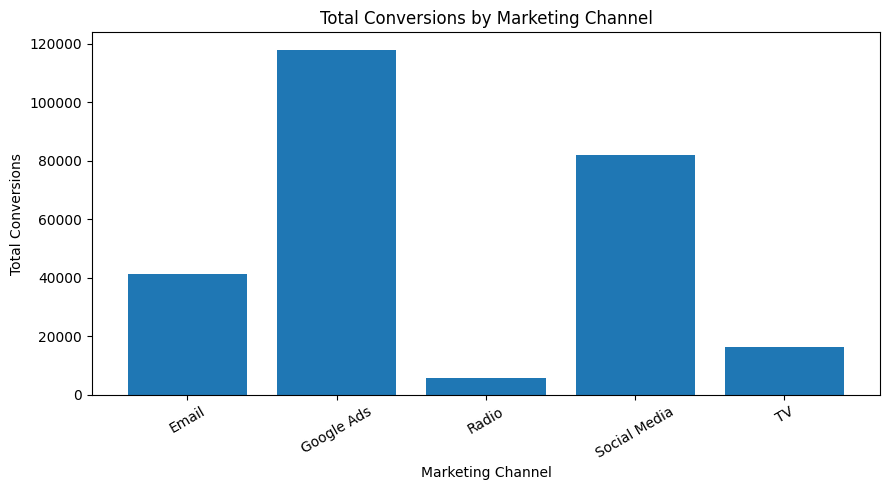

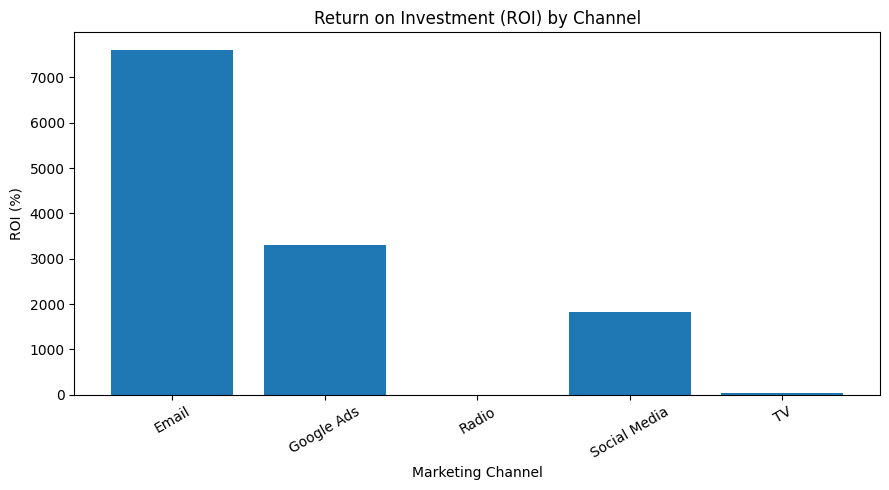

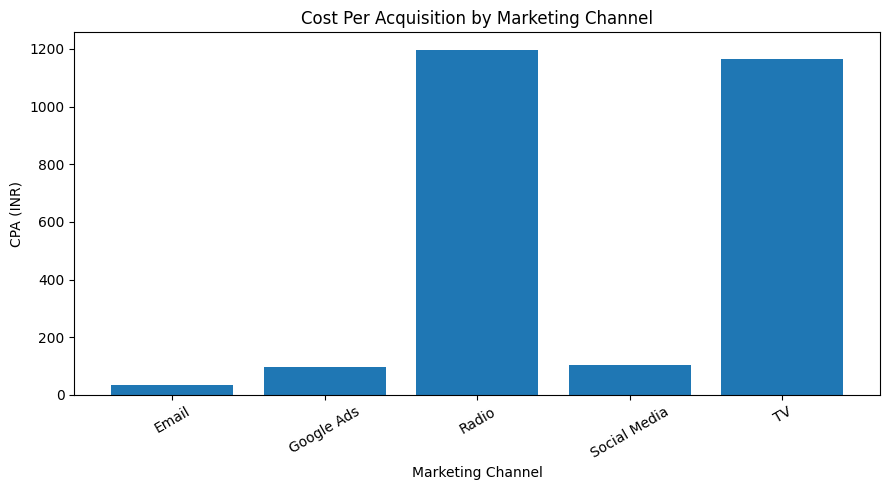

In [23]:
import matplotlib.pyplot as plt

# Chart 1: Total Conversions by Channel
plt.figure(figsize=(9, 5))
plt.bar(
    channel_analysis['Channel'],
    channel_analysis['Conversions']
)
plt.title('Total Conversions by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Total Conversions')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 2: ROI by Channel
plt.figure(figsize=(9, 5))
plt.bar(
    channel_analysis['Channel'],
    channel_analysis['ROI (%)']
)
plt.title('Return on Investment (ROI) by Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('ROI (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Chart 3: Cost Per Acquisition by Channel
plt.figure(figsize=(9, 5))
plt.bar(
    channel_analysis['Channel'],
    channel_analysis['CPA (INR)']
)
plt.title('Cost Per Acquisition by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('CPA (INR)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

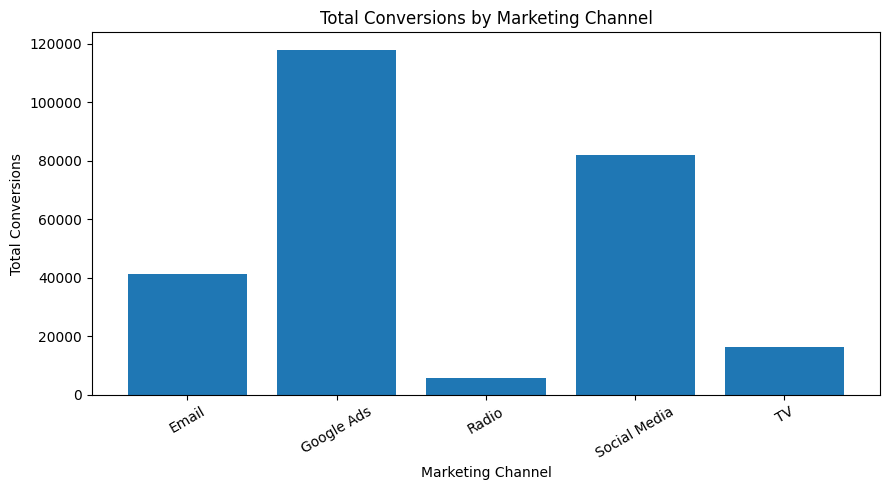

In [24]:
plt.figure(figsize=(9, 5))

plt.bar(
    channel_analysis['Channel'],
    channel_analysis['Conversions']
)

plt.title('Total Conversions by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Total Conversions')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [25]:
funnel = {
    'Stage': ['Impressions', 'Clicks', 'Conversions'],
    'Count': [
        df['Impressions'].sum(),
        df['Clicks'].sum(),
        df['Conversions'].sum()
    ]
}

funnel_df = pd.DataFrame(funnel)

display(funnel_df)

# Calculate funnel conversion percentages
print("Click-through rate:",
      round(funnel_df.loc[1, 'Count'] /
            funnel_df.loc[0, 'Count'] * 100, 2), "%")

print("Click-to-conversion rate:",
      round(funnel_df.loc[2, 'Count'] /
            funnel_df.loc[1, 'Count'] * 100, 2), "%")

,Stage,Count
0,Impressions,641194842.0
1,Clicks,4790959.0
2,Conversions,263224.0


Click-through rate: 0.75 %
Click-to-conversion rate: 5.49 %
